# Quantum walks: explicit circuits and independent checks

The default coined walk uses 3 position bits, one coin, 4 steps, start position0 and coin $(|0\rangle+i|1\rangle)/\sqrt2$. Controlled binary carries implement the cycle shifts; no dense shift matrix constructs a gate. The separate continuous-time example uses the3-dimensional hypercube $H=\sum_jX_j$, time0.7. These are different graph/evolution tasks, without a speedup comparison.

In [1]:
from pathlib import Path
import sys, os, json
root=Path.cwd()
if (root/"src").exists(): sys.path.insert(0,str(root/"src"))
from openquantum.quantum_walks import (
    build_conditional_shift, build_coined_walk, lower_walk, simulate_coined_walk,
    classical_cycle_distribution, coined_observable_budget, sample_position_outcomes)
from openquantum.quantum_walks_continuous import (
    build_continuous_walk, validate_continuous_walk, analytic_continuous_distribution,
    continuous_observable_budget)
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
n,steps=3,4
walk=build_coined_walk(n,steps)
result=simulate_coined_walk(n,steps)
classical=classical_cycle_distribution(n,steps)
np.testing.assert_allclose(result["probabilities"],[1/8,0,3/8,0,1/8,0,3/8,0],atol=3e-12,rtol=0)
print("Actual and independent references agree.")

Actual and independent references agree.


## The actual conditional shift

Position uses q0..q2; coin uses q3. Coin0 decrements modulo8; coin1 increments. Carries run high-to-low for increment and in reverse for decrement. There are no scratch wires.

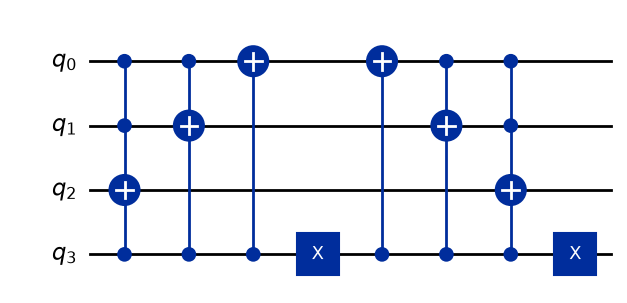

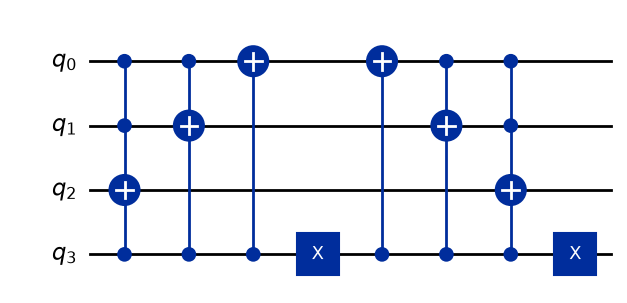

In [2]:
figure=build_conditional_shift(n).draw(output="mpl",fold=28)
display(figure)

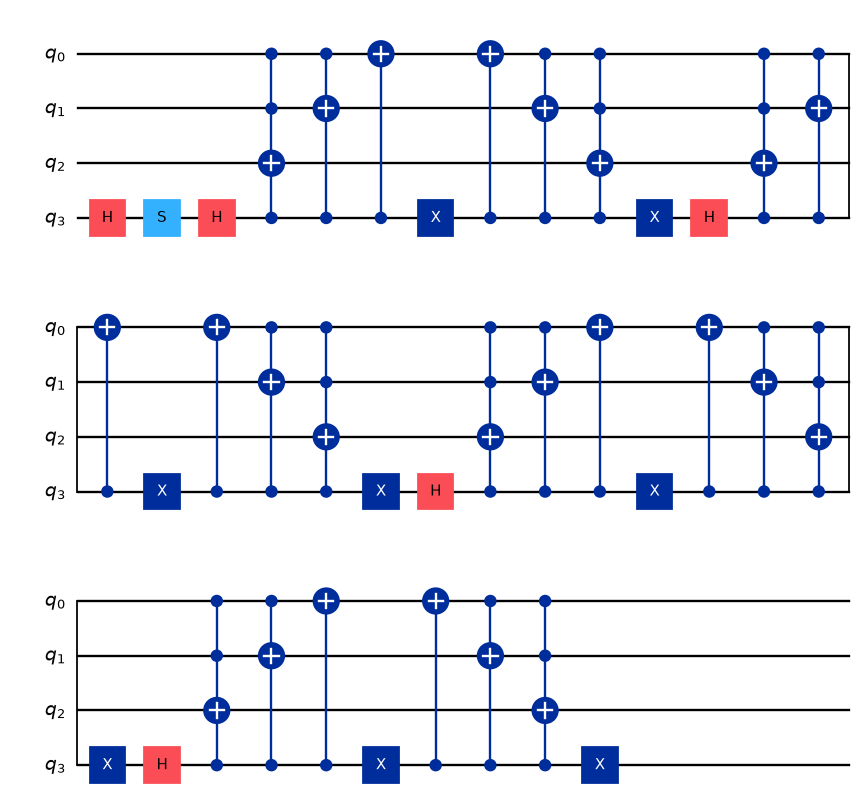

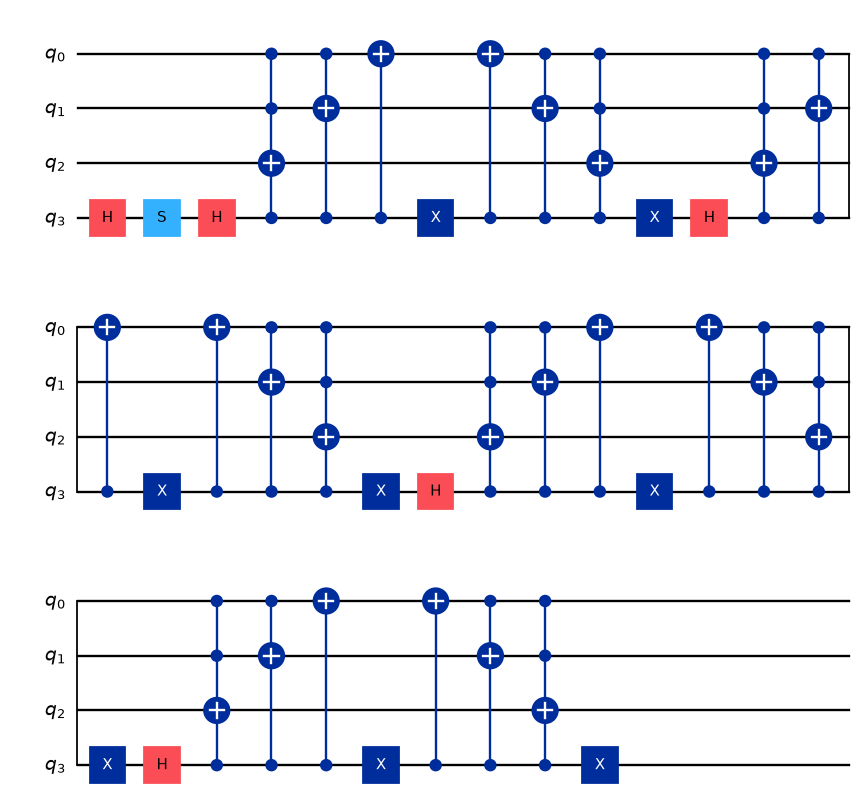

In [3]:
figure=walk.draw(output="mpl",fold=14,scale=.85)
display(figure)

## Interference versus classical probabilities

The plotted full histogram is a bounded illustration. Resource statistics below estimate only one fixed return-event probability. Neither coin output is postselected.

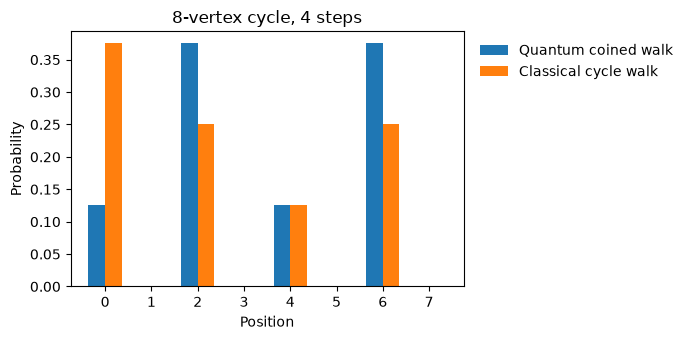

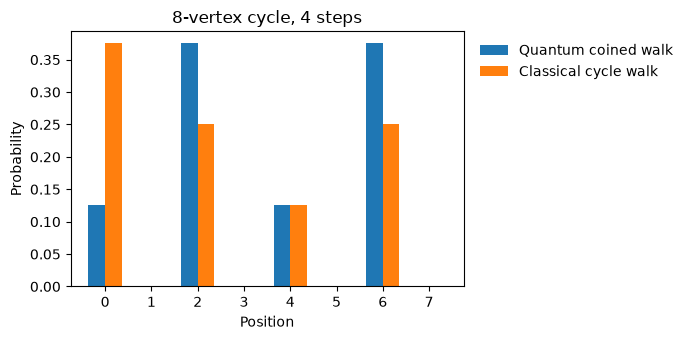

In [4]:
positions=np.arange(1<<n)
fig,ax=plt.subplots(figsize=(7,3.5))
ax.bar(positions-.18,result["probabilities"],width=.36,label="Quantum coined walk")
ax.bar(positions+.18,classical,width=.36,label="Classical cycle walk")
ax.set(xlabel="Position",ylabel="Probability",title="8-vertex cycle, 4 steps")
ax.legend(loc="upper left",bbox_to_anchor=(1.01,1),frameon=False);fig.tight_layout();display(fig)

In [5]:
print("Return probability, quantum:",result["return_probability"])
print("Return probability, classical:",float(classical[0]))
print("Independent amplitude-recurrence max error:",result["independent_amplitude_recurrence_max_error"])
print("Independent dense matrix max error:",result["state_amplitude_max_error"])
print("Total probability:",result["probabilities"].sum())

Return probability, quantum: 0.12499999999999944
Return probability, classical: 0.375
Independent amplitude-recurrence max error: 1.246531298897714e-15
Independent dense matrix max error: 1.1322097734007353e-15
Total probability: 0.9999999999999953


## Continuous-time hypercube variant

For $H=J\sum_jX_j$, commuting terms give $R_X(2Jt)$ per position bit. The source circuit uses no matrix-exponential gate. The independent dense reference builds bit-flip edges and exponentiates their adjacency.

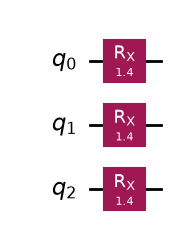

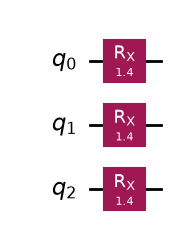

In [6]:
ct=build_continuous_walk(3,.7)
ct_result=validate_continuous_walk(3,.7)
figure=ct.draw(output="mpl")
display(figure)

In [7]:
print("Hypercube return at Jt=.7:",ct_result["return_probability"])
print("Independent analytic probability:",ct_result["analytic_return_probability"])
print("Independent operator error:",ct_result["operator_max_absolute_error"])
uniform=validate_continuous_walk(3,np.pi/4)
np.testing.assert_allclose(uniform["probabilities"],np.ones(8)/8,atol=1e-12,rtol=0)
print("Uniform probabilities at Jt=pi/4:",uniform["probabilities"])
print("Normalized adjacency J=1/n instead reaches this point at time pi*n/4.")

Hypercube return at Jt=.7: 0.20018475869221777
Independent analytic probability: 0.2001847586922178
Independent operator error: 2.220446049250313e-16
Uniform probabilities at Jt=pi/4: [0.12500000000000006, 0.12500000000000003, 0.12500000000000003, 0.12499999999999997, 0.12500000000000003, 0.12499999999999997, 0.12499999999999997, 0.12499999999999994]
Normalized adjacency J=1/n instead reaches this point at time pi*n/4.


## Complete measured trials and resource boundaries

Both models estimate one return indicator in[0,1]. At sampling error0.03/failure0.005, Hoeffding requests3329 fresh independent outputs. Synthesis model allowance1e-4 gives conditional total accuracy0.0301; separate physical-fault allowance0.005 spans allshots. This is a mean-fit resource model, not a concrete synthesis/accuracy certificate. Initialization/reset timing and faults, routing and classical control/communication remain excluded. Counts below include all source preparation, evolution and final measurement.

In [8]:
budget=coined_observable_budget()
ct_budget=continuous_observable_budget(synthesis_bias=1e-4)
assert budget.shots_required==ct_budget.shots_required==3329
measured=lower_walk(build_coined_walk(3,4,measure=True))
print("Complete trial qubits:",measured.num_qubits)
print("Primitive gates/readouts per trial:",dict(measured.count_ops()))
print("Dependency depth (not hardware runtime):",measured.depth())
print("All3329-trial operation count:",len(measured.data)*budget.shots_required)
counts=sample_position_outcomes(result["probabilities"],budget.shots_required,seed=731)
print("Seeded classical categorical counts from the ideal marginal:",counts)
print("Sampled return mean:",counts[0]/counts.sum())
print("Certified confidence:",budget.as_contract()["certified_confidence_lower_bound"])
report=root/"assets/generated/quantum-walks/surface-code-scaling.json"
if report.exists():
    data=json.loads(report.read_text())
    print("Conditional physical queries recorded:",data["query_count"])
else:
    print("Physical queries are separate optional artifacts; this notebook does not require QDK.")

Complete trial qubits: 4
Primitive gates/readouts per trial: {'cx': 160, 'rz': 124, 't': 28, 'tdg': 24, 'h': 10, 'x': 5, 'measure': 4, 'ry': 3, 'rx': 1}
Dependency depth (not hardware runtime): 294
All3329-trial operation count: 1195111
Seeded classical categorical counts from the ideal marginal: [ 399    0 1233    0  432    0 1265    0]
Sampled return mean: 0.11985581255632322
Certified confidence: None
Conditional physical queries recorded: 24


## Optional live exploration

A local or Binder kernel can change the register and step count, rerun the actual circuit and compare it with its independent recurrence. The static build deliberately omits kernel-backed controls. No web-server backend is required for the saved page.

In [9]:
if os.environ.get("OPENQUANTUM_STATIC_BUILD")!="1":
    import ipywidgets as widgets
    def explore(position_bits=3,step_count=4):
        check=simulate_coined_walk(position_bits,step_count)
        p=np.arange(1<<position_bits)
        figure,axis=plt.subplots(figsize=(7,3.3))
        axis.bar(p,check["probabilities"])
        axis.set(xlabel="Position",ylabel="Quantum probability",title=f"{1<<position_bits} vertices, {step_count} steps")
        figure.tight_layout();display(figure)
        print("Independent recurrence residual:",check["independent_amplitude_recurrence_max_error"])
    display(widgets.interactive(explore,
        position_bits=widgets.IntSlider(value=3,min=2,max=5,continuous_update=False),
        step_count=widgets.IntSlider(value=4,min=0,max=16,continuous_update=False)))
else:
    print("Live controls omitted in static execution.")

Live controls omitted in static execution.


## Reproduce and generate separately from simulation

Use the pinned Python3.12 environment and public code package. Canonical artifacts: `python scripts/generate_quantum_walks.py --estimate`. Circuit-only example: `python scripts/generate_quantum_walks.py --qubits 10 --steps 2 --no-sim --no-scaling --output-dir artifacts/walk-10`.

Cycle generation permits12 position bits/256steps with a conservative source-work guard and250000 expanded-operation cap; simulation stops at12totalwires/64steps. Hypercube generation permits64bits; full probability arrays/statevectors/dense references have smaller independent limits. No Lean proof or general-graph advantage is claimed.